In [89]:
# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [90]:
# Step 1 - Loading and Preprocessing

diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe().T)

Dataset shape: (442, 11)

First five rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Column names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


In [91]:
# Separate independent variables (X) and target (y)

X = df.drop(columns="target")
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target range:", y.min(), "to", y.max())

# No missing values are expected in this built-in dataset.
# If missing values were present, they would need to be imputed before scaling.
if X.isnull().sum().sum() > 0 or y.isnull().sum() > 0:
    print("Missing values detected; handle them before continuing.")
else:
    print("No missing values found.")

Feature shape: (442, 10)
Target shape: (442,)
Target range: 25.0 to 346.0
No missing values found.


In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Number of input features:", X_train_scaled.shape[1])

Training samples: 353
Testing samples: 89
Number of input features: 10


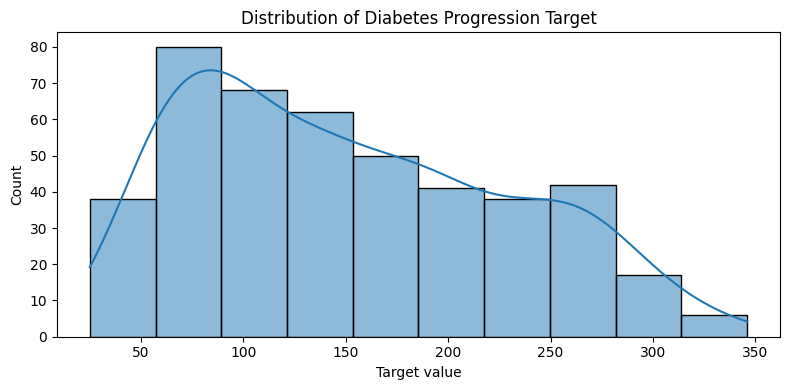

In [93]:
# Step 2 - Exploratory Data Analysis (EDA)

# Distribution of the target
plt.figure(figsize=(8, 4))
sns.histplot(y, kde=True)
plt.title("Distribution of Diabetes Progression Target")
plt.xlabel("Target value")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

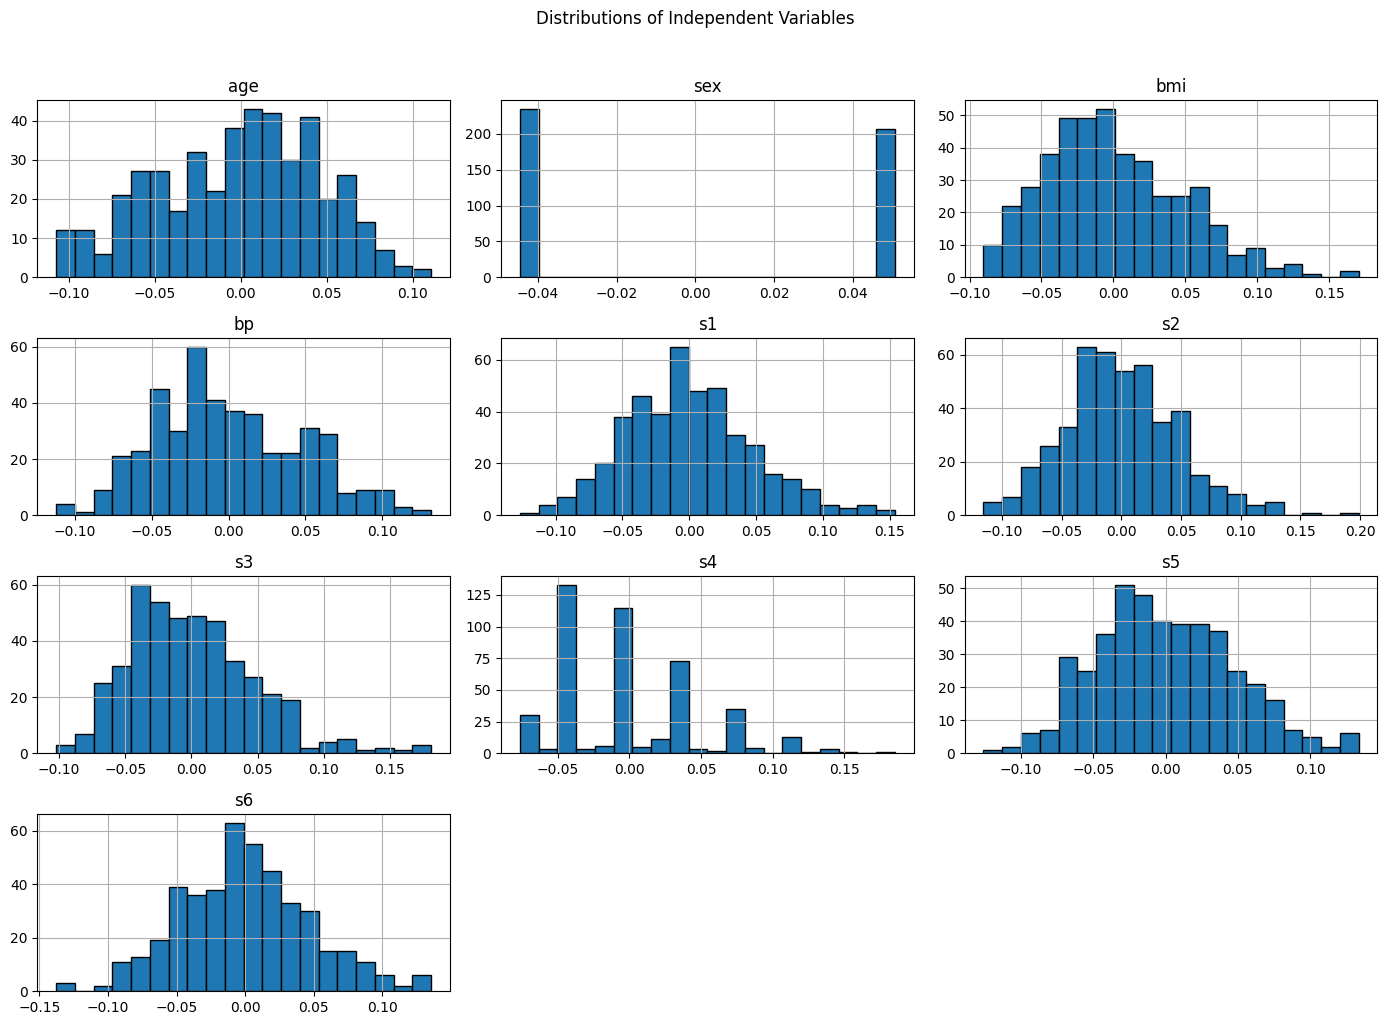

In [94]:
# Distributions of all independent variables
X.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of Independent Variables", y=1.02)
plt.tight_layout()
plt.show()

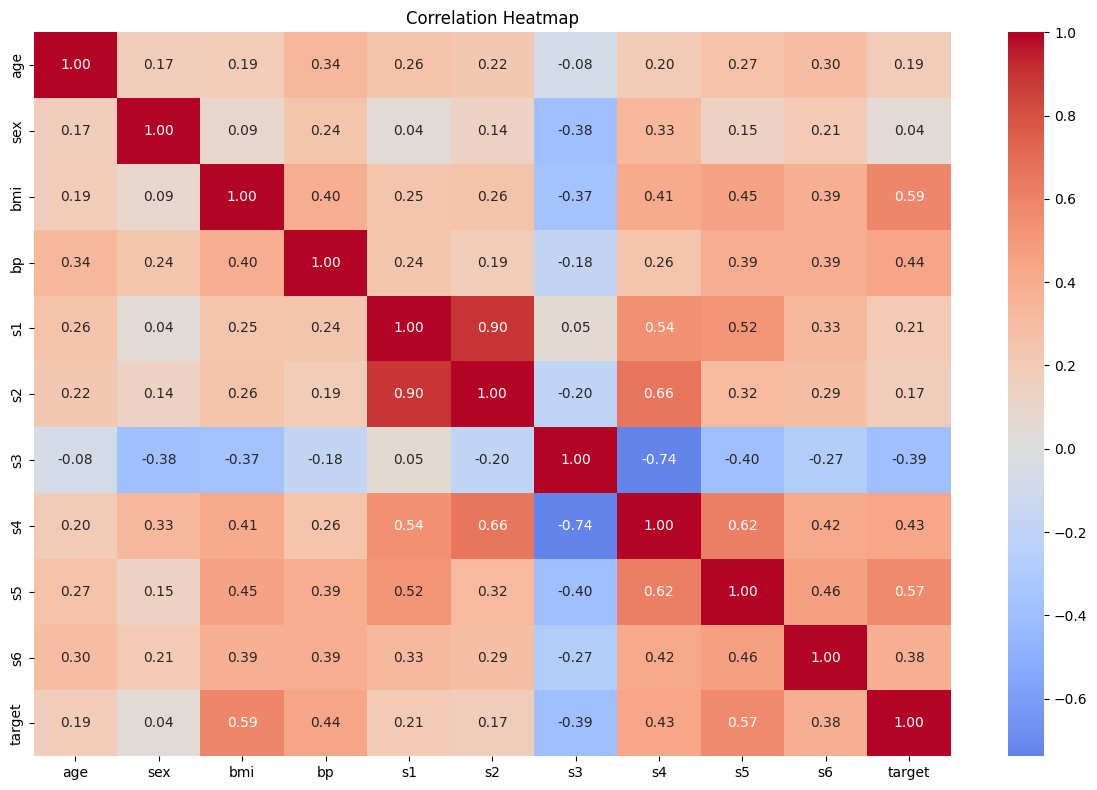

Correlations with target, sorted by absolute value:


,correlation_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


In [95]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlations with target, sorted by absolute value:")
display(corr["target"].drop("target").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_target"))

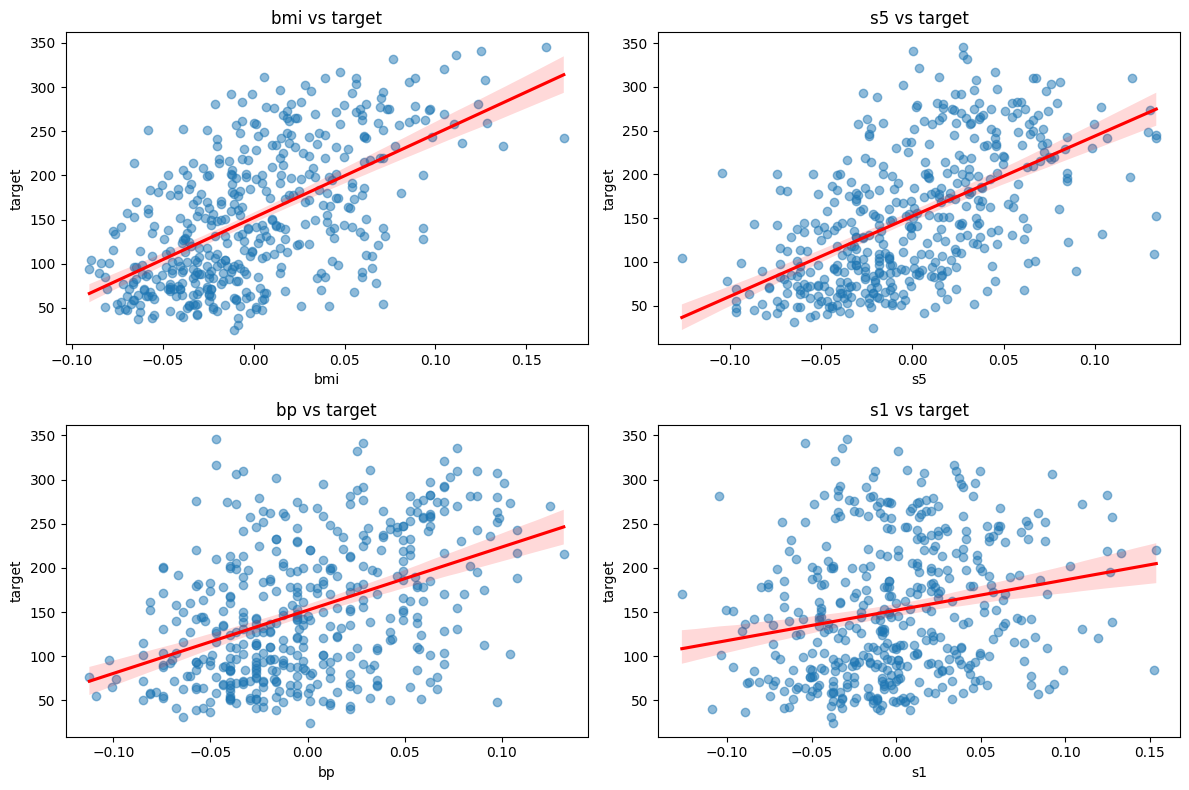

In [96]:
selected_features = ["bmi", "s5", "bp", "s1"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected_features, axes.flatten()):
    sns.regplot(data=df, x=feature, y="target", scatter_kws={"alpha": 0.5}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{feature} vs target")
plt.tight_layout()
plt.show()

In [97]:
# Step 3 - Building the ANN Model

def build_baseline_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="linear")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )
    return model

baseline_model = build_baseline_model(X_train_scaled.shape[1])
baseline_model.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_38 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

In [98]:
# Step 4 - Training the ANN Model

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history_baseline = baseline_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=300,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

print("Baseline epochs trained:", len(history_baseline.history["loss"]))
print("Best validation MSE:", min(history_baseline.history["val_loss"]))



Baseline epochs trained: 300
Best validation MSE: 2949.59326171875


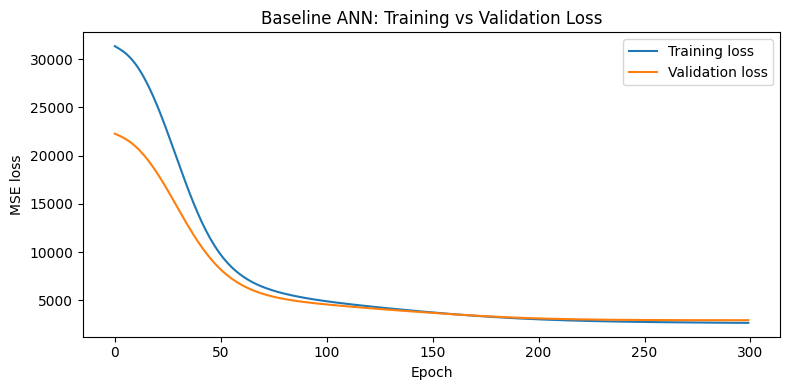

In [99]:
# Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history_baseline.history["loss"], label="Training loss")
plt.plot(history_baseline.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Baseline ANN: Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [100]:
# Step 5 - Evaluating the Model

def evaluate_regression(model, X_eval, y_eval, model_name):
    predictions = model.predict(X_eval, verbose=0).reshape(-1)
    mse = mean_squared_error(y_eval, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_eval, predictions)
    r2 = r2_score(y_eval, predictions)
    return {
        "Model": model_name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }, predictions

baseline_results, baseline_predictions = evaluate_regression(
    baseline_model, X_test_scaled, y_test, "Baseline ANN"
)
display(pd.DataFrame([baseline_results]).set_index("Model"))

,MSE,RMSE,MAE,R2
Model,,,,
Baseline ANN,2958.296509,54.390224,42.854437,0.441636


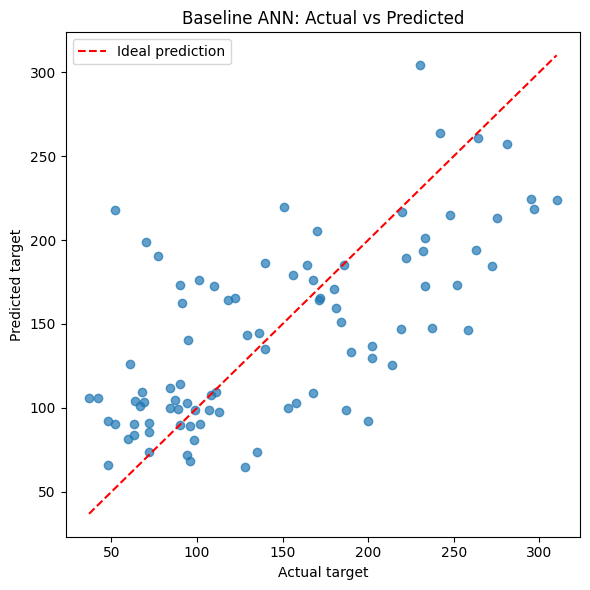

In [101]:
# Actual vs predicted values for baseline
plt.figure(figsize=(6, 6))
plt.scatter(y_test, baseline_predictions, alpha=0.7)
min_val = min(y_test.min(), baseline_predictions.min())
max_val = max(y_test.max(), baseline_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Ideal prediction")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Baseline ANN: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

In [102]:
# Step 6 - Improving the Model

def build_improved_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="linear")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="mse",
        metrics=["mae"]
    )
    return model

improved_model = build_improved_model(X_train_scaled.shape[1])
improved_model.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_40 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [103]:
tf.random.set_seed(SEED)
history_improved = improved_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=400,
    batch_size=16,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=30, restore_best_weights=True
    )],
    verbose=0
)

print("Improved model epochs trained:", len(history_improved.history["loss"]))
print("Best validation MSE:", min(history_improved.history["val_loss"]))

Improved model epochs trained: 146
Best validation MSE: 2849.523681640625


In [104]:
improved_results, improved_predictions = evaluate_regression(
    improved_model, X_test_scaled, y_test, "Improved ANN"
)

comparison = pd.DataFrame([baseline_results, improved_results]).set_index("Model")
display(comparison.round(3))

,MSE,RMSE,MAE,R2
Model,,,,
Baseline ANN,2958.297,54.390,42.854,0.442
Improved ANN,2986.251,54.647,43.589,0.436


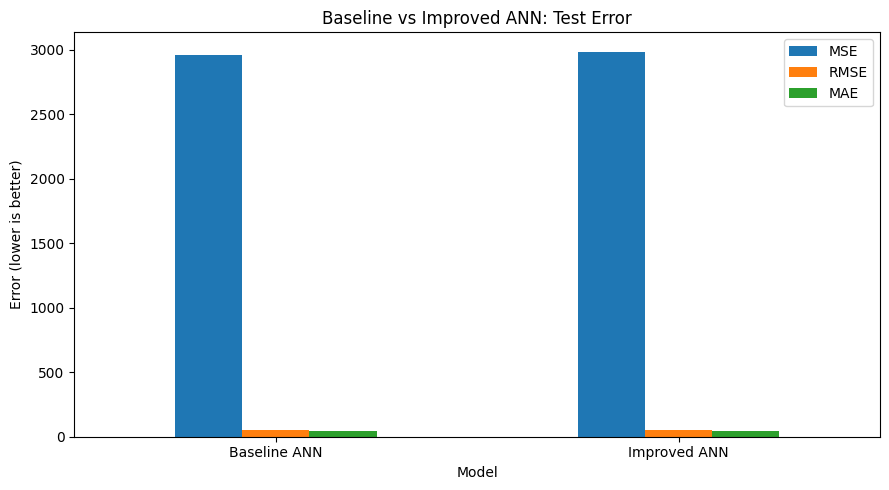

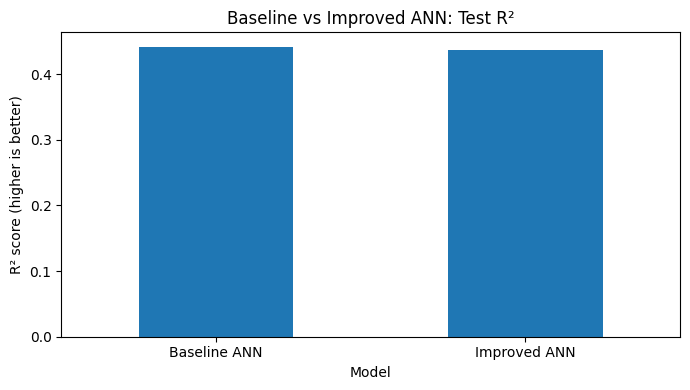

In [105]:
# Compare model test metrics visually
comparison[["MSE", "RMSE", "MAE"]].plot(kind="bar", figsize=(9, 5))
plt.ylabel("Error (lower is better)")
plt.title("Baseline vs Improved ANN: Test Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison[["R2"]].plot(kind="bar", figsize=(7, 4), legend=False)
plt.ylabel("R² score (higher is better)")
plt.title("Baseline vs Improved ANN: Test R²")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [106]:
best_mse_model = comparison["MSE"].idxmin()
best_r2_model = comparison["R2"].idxmax()

print("Lower test MSE:", best_mse_model)
print("Higher test R²:", best_r2_model)

mse_change_pct = (
    (baseline_results["MSE"] - improved_results["MSE"]) /
    baseline_results["MSE"] * 100
)
r2_change = improved_results["R2"] - baseline_results["R2"]

print("Change in MSE from baseline to improved: {mse_change_pct:.2f}% (positive means MSE decreased)")
print("Change in R² from baseline to improved: {r2_change:.4f} (positive means R² increased)")

if improved_results["MSE"] < baseline_results["MSE"] and improved_results["R2"] > baseline_results["R2"]:
    print("The improved model performed better on both MSE and R² for this split.")
else:
    print("The improved model did not improve both metrics. Architecture changes do not guarantee better results.")

Lower test MSE: Baseline ANN
Higher test R²: Baseline ANN
Change in MSE from baseline to improved: {mse_change_pct:.2f}% (positive means MSE decreased)
Change in R² from baseline to improved: {r2_change:.4f} (positive means R² increased)
The improved model did not improve both metrics. Architecture changes do not guarantee better results.


In [107]:

# Experiment 3: Smaller ANN with 16 neurons

tf.random.set_seed(SEED)

def build_small_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="linear")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model

small_model = build_small_model(X_train_scaled.shape[1])

small_history = small_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=300,
    batch_size=16,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=25,
            restore_best_weights=True
        )
    ],
    verbose=0
)

small_results, small_predictions = evaluate_regression(
    small_model,
    X_test_scaled,
    y_test,
    "Smaller ANN (16 neurons)"
)

print("Epochs trained:", len(small_history.history["loss"]))
display(pd.DataFrame([small_results]).set_index("Model").round(3))


Epochs trained: 300


,MSE,RMSE,MAE,R2
Model,,,,
Smaller ANN (16 neurons),3441.796,58.667,46.182,0.35


In [108]:

# Experiment 4: ANN with L2 regularization

tf.random.set_seed(SEED)

def build_regularized_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.01)
        ),
        tf.keras.layers.Dense(1, activation="linear")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model

regularized_model = build_regularized_model(
    X_train_scaled.shape[1]
)

regularized_history = regularized_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=300,
    batch_size=16,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=25,
            restore_best_weights=True
        )
    ],
    verbose=0
)

regularized_results, regularized_predictions = evaluate_regression(
    regularized_model,
    X_test_scaled,
    y_test,
    "L2 Regularized ANN"
)

print("Epochs trained:", len(regularized_history.history["loss"]))
display(
    pd.DataFrame([regularized_results])
    .set_index("Model")
    .round(3)
)


Epochs trained: 276


,MSE,RMSE,MAE,R2
Model,,,,
L2 Regularized ANN,2970.503,54.502,43.398,0.439


In [109]:

# Compare all four ANN experiments

all_results = pd.DataFrame([
    baseline_results,
    improved_results,
    small_results,
    regularized_results
]).set_index("Model")

display(all_results.round(3))

print("Best model by test MSE:")
print(all_results["MSE"].idxmin())

print("\nBest model by test R2:")
print(all_results["R2"].idxmax())


,MSE,RMSE,MAE,R2
Model,,,,
Baseline ANN,2958.297,54.390,42.854,0.442
Improved ANN,2986.251,54.647,43.589,0.436
Smaller ANN (16 neurons),3441.796,58.667,46.182,0.350
L2 Regularized ANN,2970.503,54.502,43.398,0.439


Best model by test MSE:
Baseline ANN

Best model by test R2:
Baseline ANN
